<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-10/lab-061-cartpole.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 061. CartPole observations, rewards and policy updates
We balance a pole by pushing its cart left or right. This experiment comes before quantum state preparation. We connect a visible mechanical task to observations, actions, returns and a sampled policy update.

The notebook uses Gymnasium CartPole-v1 with its default reward. Install the classic-control rendering dependencies if needed, using `pip install "gymnasium[classic-control]" torch matplotlib`. Run cells in order from the course Notebooks directory. The core route makes no long training run. It evaluates the existing recorded policy when `results/cp_snapshots.pt` is available, and performs one new REINFORCE update on a fresh policy. The optional complete training study remains in `appendix/Policy_gradient_cartpole.ipynb`.

Gymnasium 1.4.0 ; PyTorch 2.9.0+cpu
Observation [x, x_dot, theta, theta_dot]: [-0.01503614 -0.00751029 -0.04824638 -0.0440781 ]
Allowed actions: Discrete(2) ; maximum evaluation steps: 500


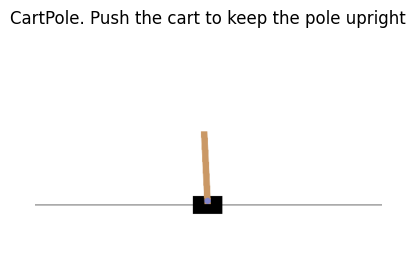

In [1]:
import os,json,time
from pathlib import Path
os.environ.setdefault('SDL_VIDEODRIVER','dummy')
os.environ.setdefault('SDL_AUDIODRIVER','dummy')
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from torch import nn
torch.set_num_threads(2)
ROOT=Path.cwd(); OUT=ROOT/'classroom_results';OUT.mkdir(exist_ok=True)
FIG=ROOT/'figures';FIG.mkdir(exist_ok=True)
started=time.perf_counter()
print('Gymnasium',gym.__version__,'; PyTorch',torch.__version__)
def save_plot(fig,name):
    for ext in ['pdf','png']:fig.savefig(FIG/(name+'.'+ext),bbox_inches='tight',dpi=160)
ENV='CartPole-v1'
env=gym.make(ENV,render_mode='rgb_array')
initial,_=env.reset(seed=610)
initial_frame=env.render();plt.imsave(FIG/'cartpole_environment.png',initial_frame)
print('Observation [x, x_dot, theta, theta_dot]:',initial)
print('Allowed actions:',env.action_space,'; maximum evaluation steps:',env.spec.max_episode_steps)
fig,ax=plt.subplots(figsize=(6,3));ax.imshow(initial_frame);ax.axis('off');ax.set_title('CartPole. Push the cart to keep the pole upright');plt.show()
env.close()


## The agent and the environment
The simulator advances a cart and hinged pole under gravity. The actor receives four numbers, $s=(x,\dot x,\theta,\dot\theta)$, with angle measured from the upright position. It receives no image. The screenshot shows the apparatus for the reader.

Action 0 pushes the cart to the left and action 1 to the right, each with a force of 10 N. Each decision advances 0.02 seconds. The default reward is +1 per step, including the failure transition. The task terminates when the cart position leaves $|x|\le2.4$ m or the pole tilt leaves $|\theta|\le12^\circ$. The wrapper truncates evaluation after 500 steps. A 500-step return describes survival throughout that evaluation window.

The observed position and angle alone omit their velocities. Two visually similar configurations can require opposite pushes when the pole is moving in opposite directions. Four observations allow the controller to respond to that motion. The trace below reports physical termination and time truncation separately.

For $T$ rewards equal to one, the undiscounted return is $T$. The discounted return is $(1-\gamma^T)/(1-\gamma)$ for $\gamma<1$. The reward is simple, while learning still depends on the action sequence determining the episode length. See the [environment specification](https://gymnasium.farama.org/environments/classic_control/cart_pole/).

In [2]:
def rollout(policy,seed,record=False):
    e=gym.make(ENV,render_mode='rgb_array' if record else None)
    s,_=e.reset(seed=seed);states=[];actions=[];rewards=[];frames=[]
    terminated=truncated=False
    while not (terminated or truncated):
        if record:frames.append(e.render())
        a=int(policy(s));states.append(np.array(s));actions.append(a)
        s,r,terminated,truncated,_=e.step(a);rewards.append(float(r))
    if record:frames.append(e.render())
    e.close()
    return dict(states=np.array(states),actions=np.array(actions),rewards=np.array(rewards),
                frames=frames,terminated=bool(terminated),truncated=bool(truncated))
rng=np.random.default_rng(611)
random_trace=rollout(lambda s:rng.integers(2),611,record=True)
for t in range(min(5,len(random_trace['rewards']))):
    print('step',t,'s',np.round(random_trace['states'][t],3),'action',random_trace['actions'][t],'reward',random_trace['rewards'][t])
T=len(random_trace['rewards']);gamma=.99
assert np.isclose(np.dot(gamma**np.arange(T),random_trace['rewards']),(1-gamma**T)/(1-gamma))
print('Random episode length',T,'terminated',random_trace['terminated'],'truncated',random_trace['truncated'])


step 0 s [ 0.022  0.031 -0.018 -0.045] action 1 reward 1.0
step 1 s [ 0.022  0.226 -0.019 -0.343] action 1 reward 1.0
step 2 s [ 0.027  0.421 -0.026 -0.642] action 0 reward 1.0
step 3 s [ 0.035  0.227 -0.039 -0.357] action 1 reward 1.0
step 4 s [ 0.04   0.422 -0.046 -0.662] action 0 reward 1.0
Random episode length 31 terminated True truncated False


## A recorded policy and fresh evaluation
The recorded actor maps four observations to two action logits through two tanh hidden layers. A softmax converts the logits to probabilities. We load its saved parameters and take the most probable action for deterministic evaluation. The saved actor is seed 0 after 600 episodes of REINFORCE with a learned value baseline and $\gamma=0.99$, from `appendix/Policy_gradient_cartpole.ipynb`.

Twenty fresh reset seeds supply the evaluation set. We report individual returns, their mean and the number of episodes that reach the wrapper limit. These describe this saved policy in the installed environment version.

random {'returns': [16, 12, 47, 15, 14, 16, 10, 24, 40, 20, 14, 33, 17, 36, 17, 16, 11, 12, 42, 14], 'mean': 21.3, 'SE': 2.5793716085001868, 'reached_time_limit': 0}
recorded actor {'returns': [500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500], 'mean': 500.0, 'SE': 0.0, 'reached_time_limit': 20}


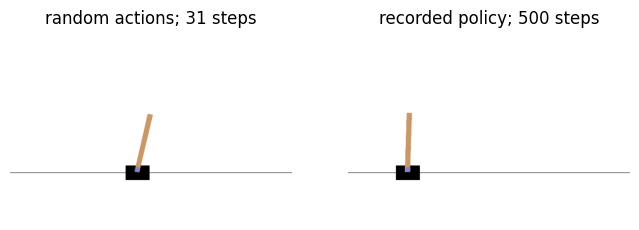

In [3]:
class Policy(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(4,64),nn.Tanh(),nn.Linear(64,64),nn.Tanh(),nn.Linear(64,2))
    def forward(self,s):return self.net(s)
checkpoint=ROOT/'results/cp_snapshots.pt';recorded=None
if checkpoint.exists():
    snapshots=torch.load(checkpoint,map_location='cpu',weights_only=True)
    recorded=Policy();recorded.load_state_dict(snapshots[max(snapshots)]);recorded.eval()
def greedy(s):
    with torch.no_grad():return int(recorded(torch.as_tensor(s,dtype=torch.float32)).argmax())
seeds=list(range(6100,6120));evaluation={}
for name,policy in [('random',lambda s: rng.integers(2))]+([('recorded actor',greedy)] if recorded is not None else []):
    runs=[rollout(policy,seed) for seed in seeds]
    values=[len(r['rewards']) for r in runs]
    evaluation[name]={'returns':values,'mean':float(np.mean(values)),
                      'SE':float(np.std(values,ddof=1)/np.sqrt(len(values))),
                      'reached_time_limit':sum(r['truncated'] and not r['terminated'] for r in runs)}
    print(name,evaluation[name])
if recorded is not None:
    trained_trace=rollout(greedy,6100,record=True)
    fig,axes=plt.subplots(1,2,figsize=(8,2.8))
    for ax,trace,title in zip(axes,[random_trace,trained_trace],['random actions','recorded policy']):
        ax.imshow(trace['frames'][-1]);ax.set_title(title+'; '+str(len(trace['rewards']))+' steps');ax.axis('off')
    save_plot(fig,'fig_cartpole_behaviour');plt.show()


The random policy survives $21.3\pm2.6$ steps on average and never reaches the limit. The saved actor reaches the 500-step limit in all 20 evaluation episodes. These numbers describe one saved policy in Gymnasium 1.4.0.

## One new policy-gradient update
We initialise a fresh actor and collect eight independent episodes. Each action's log probability is weighted by its discounted reward-to-go and by $\gamma^t$, as derived in the notes. Returns and sampled states are held fixed during this gradient calculation. This update uses no baseline, making its relationship to the derivation explicit. The appendix training that produced the saved actor weights each log probability by $G_t-V(s_t)$ without the factor $\gamma^t$. That common practical choice differs from the gradient of the discounted return from the initial state, which the $\gamma^t$-weighted estimator below estimates without bias.

The scalar surrogate loss supplies the score estimator. Its numerical value is not the expected return. After one update we inspect action probabilities at the same observation. One update establishes neither convergence nor reliable balancing.

In [4]:
torch.manual_seed(612);fresh=Policy();opt=torch.optim.Adam(fresh.parameters(),lr=1e-3)
batch=[]
for seed in range(6120,6128):
    def sampled(s):
        with torch.no_grad():return int(torch.distributions.Categorical(logits=fresh(torch.as_tensor(s,dtype=torch.float32))).sample())
    batch.append(rollout(sampled,seed))
probe=torch.as_tensor(batch[0]['states'][0],dtype=torch.float32)
before=torch.softmax(fresh(probe),-1).detach().numpy()
loss=0.
for trace in batch:
    r=trace['rewards'];G=np.zeros_like(r);g=0.
    for t in reversed(range(len(r))):g=r[t]+gamma*g;G[t]=g
    states=torch.as_tensor(trace['states'],dtype=torch.float32)
    acts=torch.as_tensor(trace['actions'])
    weight=torch.as_tensor(gamma**np.arange(len(r))*G,dtype=torch.float32)
    logp=torch.distributions.Categorical(logits=fresh(states)).log_prob(acts)
    loss=loss-(weight*logp).sum()/len(batch)
opt.zero_grad();loss.backward();opt.step()
after=torch.softmax(fresh(probe),-1).detach().numpy()
print('Batch episode lengths',[len(t['rewards']) for t in batch])
print('Action probabilities at a fixed observation before and after',before,after)
assert np.isclose(after.sum(),1)
summary={'environment':ENV,'gymnasium':gym.__version__,'initial_observation':initial.tolist(),
         'new_training':'one REINFORCE update of a fresh actor, eight episodes',
         'evaluation_seeds':seeds,'evaluation':evaluation,'runtime_seconds':time.perf_counter()-started}
(OUT/'lab061_results.json').write_text(json.dumps(summary,indent=2))
print('Core route complete. Optional full training is in appendix/Policy_gradient_cartpole.ipynb.')


Batch episode lengths [38, 17, 19, 25, 22, 12, 28, 24]
Action probabilities at a fixed observation before and after [0.4925114 0.5074886] [0.49531987 0.50468016]
Core route complete. Optional full training is in appendix/Policy_gradient_cartpole.ipynb.


At the probe observation the probability of pushing left changes from 0.4925 to 0.4953 after one Adam step with learning rate $10^{-3}$. Adam's first step moves every parameter by about the learning rate, so the size of this change is set mainly by the learning rate. Its direction follows the actions that preceded long reward-to-go in eight short random episodes. One small step changes the policy only slightly, which is why training repeats such updates over hundreds of episodes.

## Student calculations
Explain which velocities the screenshot cannot show. Predict the two possible actions at a fixed observation and then inspect the actor probabilities. Derive the constant-reward return. Distinguish a physical failure from a wrapper cutoff. Explain why the collected states and returns remain fixed during the score gradient. Compare the single new update with loading the previously trained policy.